In [ ]:

import pandas as pd

# 1) Créer un dataset avec :
# - des doublons exacts (ligne identique répétée)
# - des doublons partiels (même nom/prénom/date, mais ville/email différents)

data = [
    {"nom":"Belah","prenom":"samiha","date_naissance":"2002-05-10","ville":"Tanger","email":"samiha@gmail.com"},
    {"nom":"Belah","prenom":"samiha","date_naissance":"2002-05-10","ville":"Tanger","email":"samiha@gmail.com"},  # ✅ doublon exact

    {"nom":"EL AMRANI","prenom":"Yassine","date_naissance":"2001-03-02","ville":"Rabat","email":"yassine@exemple.com"},
    {"nom":"EL AMRANI","prenom":"Yassine","date_naissance":"2001-03-02","ville":"Casablanca","email":"yassine_new@exemple.com"},  # ✅ doublon partiel

    {"nom":"AHMED","prenom":"Imane","date_naissance":"2003-11-25","ville":"Fès","email":"imane@exemple.com"},
    {"nom":"AHMED","prenom":"Imane","date_naissance":"2003-11-25","ville":"Fès","email":"imane@exemple.com"},  # ✅ doublon exact

    {"nom":"AHMED","prenom":"Imane","date_naissance":"2003-11-25","ville":"Meknès","email":"imane2@exemple.com"},  # ✅ doublon partiel (même identité)
]

df = pd.DataFrame(data)

# 2) Sauvegarder en CSV dans l'environnement Colab
df.to_csv("donnees.csv", index=False)

print("✅ Fichier donnees.csv créé !")
df


✅ Fichier donnees.csv créé !


,nom,prenom,date_naissance,ville,email
0,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
1,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
2,EL AMRANI,Yassine,2001-03-02,Rabat,yassine@exemple.com
3,EL AMRANI,Yassine,2001-03-02,Casablanca,yassine_new@exemple.com
4,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
5,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
6,AHMED,Imane,2003-11-25,Meknès,imane2@exemple.com


In [ ]:

import pandas as pd
#pandas est une bibliothèque Python pour manipuler des tableaux de données (comme Excel, mais en code).
#pd te donne accès aux fonctions de pandas

# Charger les données
#lire un fichier CSV
#df = pd.read_csv('donnees.csv', sep=';')
#df = pd.read_csv('donnees.csv', encoding='utf-8')



df = pd.read_csv("donnees.csv")

print(" Données chargées :")
display(df)

# -----------------------------
# 1) Doublons EXACTS (toutes colonnes)
##Il compare chaque ligne avec celles qui la précèdent. Il retourne une série booléenne (True/False) : False = première occurrence (ligne “originale”) True = cette ligne est une copie d’une ligne déjà vue
# -----------------------------
doublons = df.duplicated()
print(f"\n Nombre de doublons EXACTS (sur toutes les colonnes) : {doublons.sum()}") #Compter combien de doublons exacts

print("\n Lignes concernées par doublons exacts (keep=False => affiche tout le groupe) :")
#afficher toutes les lignes qui ont des doublons, y compris la 1ère occurrence.
display(df[df.duplicated(keep=False)])

# -----------------------------
# 2) Doublons PARTIELS (sur certaines colonnes)
# -----------------------------
# True si une ligne répète la même combinaison (nom, prénom, date_naissance) déjà vue
doublons_partiels = df.duplicated(subset=["nom", "prenom", "date_naissance"])

## sum() compte combien de True => nombre de lignes en doublon (hors premières occurrences)
print(f"\n Nombre de doublons PARTIELS (nom+prenom+date_naissance) : {doublons_partiels.sum()}")

# keep=False => affiche TOUTES les lignes d'un groupe dupliqué (y compris la 1ère)
print("\n Toutes les lignes concernées par doublons partiels :")
display(df[df.duplicated(subset=["nom","prenom","date_naissance"], keep=False)])

# -----------------------------
# 3) Supprimer doublons : garder la première occurrence
# -----------------------------
## Supprime les doublons selon ces colonnes et garde la 1ère occurrence de chaque groupe
df_clean_first = df.drop_duplicates(subset=["nom","prenom","date_naissance"], keep="first")
print("\n Après suppression (garder la PREMIÈRE occurrence) :")

# Affiche le DataFrame nettoyé en gardant la 1ère ligne de chaque doublon
display(df_clean_first)

# -----------------------------
# 4) Supprimer doublons : garder la dernière occurrence
# -----------------------------
df_clean_last = df.drop_duplicates(subset=["nom","prenom","date_naissance"], keep="last")
print("\n Après suppression (garder la DERNIÈRE occurrence) :")
display(df_clean_last)


📌 Données chargées :


,nom,prenom,date_naissance,ville,email
0,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
1,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
2,EL AMRANI,Yassine,2001-03-02,Rabat,yassine@exemple.com
3,EL AMRANI,Yassine,2001-03-02,Casablanca,yassine_new@exemple.com
4,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
5,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
6,AHMED,Imane,2003-11-25,Meknès,imane2@exemple.com



✅ Nombre de doublons EXACTS (sur toutes les colonnes) : 2

🔎 Lignes concernées par doublons exacts (keep=False => affiche tout le groupe) :


,nom,prenom,date_naissance,ville,email
0,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
1,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
4,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
5,AHMED,Imane,2003-11-25,Fès,imane@exemple.com



✅ Nombre de doublons PARTIELS (nom+prenom+date_naissance) : 4

🔎 Toutes les lignes concernées par doublons partiels :


,nom,prenom,date_naissance,ville,email
0,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
1,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
2,EL AMRANI,Yassine,2001-03-02,Rabat,yassine@exemple.com
3,EL AMRANI,Yassine,2001-03-02,Casablanca,yassine_new@exemple.com
4,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
5,AHMED,Imane,2003-11-25,Fès,imane@exemple.com
6,AHMED,Imane,2003-11-25,Meknès,imane2@exemple.com



🧹 Après suppression (garder la PREMIÈRE occurrence) :


,nom,prenom,date_naissance,ville,email
0,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
2,EL AMRANI,Yassine,2001-03-02,Rabat,yassine@exemple.com
4,AHMED,Imane,2003-11-25,Fès,imane@exemple.com



🧹 Après suppression (garder la DERNIÈRE occurrence) :


,nom,prenom,date_naissance,ville,email
1,Belah,samiha,2002-05-10,Tanger,samiha@gmail.com
3,EL AMRANI,Yassine,2001-03-02,Casablanca,yassine_new@exemple.com
6,AHMED,Imane,2003-11-25,Meknès,imane2@exemple.com


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

# Données
data = {
    'salaire': [3000, 3200, 2800, 2900, 3100, 3050,
                2950, 3150, 2850, 3000,
                15000, 20000]
}

df = pd.DataFrame(data)

# Calculer Z-Score
df['z_score'] = np.abs(stats.zscore(df['salaire']))

# Seuil
seuil = 2

# Identifier outliers
df['is_outlier'] = df['z_score'] >= seuil

# Séparer outliers et non-outliers
outliers = df[df['is_outlier'] == True]['salaire'].tolist()
non_outliers = df[df['is_outlier'] == False]['salaire'].tolist()

# Affichage

print("DÉTECTION D'OUTLIERS")
print(f"Seuil Z-Score : {seuil}")
print()

print(f"OUTLIERS : {len(outliers)}")
print(f"   Valeurs : {outliers}")
print()

print(f"NON-OUTLIERS : {len(non_outliers)}")
print(f"   Valeurs : {non_outliers}")

DÉTECTION D'OUTLIERS
Seuil Z-Score : 1

OUTLIERS : 2
   Valeurs : [15000, 20000]

NON-OUTLIERS : 10
   Valeurs : [3000, 3200, 2800, 2900, 3100, 3050, 2950, 3150, 2850, 3000]


In [ ]:
import pandas as pd

# Données
salaires = [3000, 3200, 2800, 2900, 3100, 3050,
            2950, 3150, 2850, 3000, 15000, 20000]

df = pd.DataFrame({'salaire': salaires})

# ✅ MÉTHODE IQR (InterQuartile Range)
Q1 = df['salaire'].quantile(0.25)  # 25ème percentile
Q3 = df['salaire'].quantile(0.75)  # 75ème percentile
IQR = Q3 - Q1

#1.5 × IQR = seuil standard pour identifier les outliers

# Limites pour détecter outliers
limite_basse = Q1 - 1.5 * IQR
limite_haute = Q3 + 1.5 * IQR

# Séparer outliers et non-outliers
outliers = df[(df['salaire'] < limite_basse) | (df['salaire'] > limite_haute)]['salaire'].tolist()
non_outliers = df[(df['salaire'] >= limite_basse) & (df['salaire'] <= limite_haute)]['salaire'].tolist()

# Affichage
print("="*50)
print("DÉTECTION D'OUTLIERS - MÉTHODE IQR")
print("="*50)
print(f"Limite basse : {limite_basse:.2f}€")
print(f"Limite haute : {limite_haute:.2f}€")
print()

print(f"❌ OUTLIERS : {len(outliers)}")
print(f"   Valeurs : {outliers}")
print()

print(f"✅ NON-OUTLIERS : {len(non_outliers)}")
print(f"   Valeurs : {non_outliers}")


DÉTECTION D'OUTLIERS - MÉTHODE IQR
Limite basse : 2600.00€
Limite haute : 3500.00€

❌ OUTLIERS : 2
   Valeurs : [15000, 20000]

✅ NON-OUTLIERS : 10
   Valeurs : [3000, 3200, 2800, 2900, 3100, 3050, 2950, 3150, 2850, 3000]


In [ ]:
import pandas as pd
from sklearn.ensemble import IsolationForest

# Exemple de données
data = {
    'age': [25, 30, 28, 40, 23, 100],
    'salaire': [3000, 3200, 3100, 4000, 3050, 10000],
    'experience': [2, 5, 3, 10, 1, 50]
}

df = pd.DataFrame(data)

# Initialisation
#42, C’est juste un nombre choisi pour fixer le hasard.
#Le modèle va considérer que 20 % des données sont des outliers.
#Isolation Forest doit savoir approximativement combien d’outliers il doit chercher.

iso_forest = IsolationForest(contamination=0.2, random_state=42) # 20% anomalies pour cet exemple
outliers_if = iso_forest.fit_predict(df[['age', 'salaire', 'experience']])

# Stockage dans le DataFrame
df['outlier_if'] = outliers_if
print(df)


   age  salaire  experience  outlier_if
0   25     3000           2           1
1   30     3200           5           1
2   28     3100           3           1
3   40     4000          10           1
4   23     3050           1           1
5  100    10000          50          -1


In [ ]:
import pandas as pd
import re
#re bibliothèque pour travailler avec les expressions régulières (utile pour vérifier le format des emails).

# Données d'exemple
data = {
    'age': [25, -5],
    'date': ['2023-01-10', 'abc'],
    'pays': [' Maroc ', 'Marok'],
    'email': ['TEST@MAIL.COM', 'bademail'],
    'date_debut': ['2023-01-01', '2023-05-01'],
    'date_fin': ['2023-12-31', '2023-04-01']
}

df = pd.DataFrame(data)

# Conversion des dates
df['date'] = pd.to_datetime(df['date'], errors='coerce')//convertir les colonnes contenant des dates textuelles en véritables, Pandas la remplace par une valeur manquante de type date, appelée Na
df['date_debut'] = pd.to_datetime(df['date_debut'])
df['date_fin'] = pd.to_datetime(df['date_fin'])

# Détection erreurs
erreurs_age = df[df['age'] < 0]
erreurs_logiques = df[df['date_fin'] < df['date_debut']]

# Standardisation
df['pays'] = df['pays'].str.strip().str.upper() // strip Elle supprime les espaces au début et à la fin du texte.
df['email'] = df['email'].str.lower()

# Correction pays
corrections = {
    'MAROK': 'MAROC',
    'MARROC': 'MAROC',
    'MOROCCO': 'MAROC'
}
df['pays'] = df['pays'].replace(corrections)

# Validation email
def valider_email(email):
    pattern = r'^[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}$'
    return bool(re.match(pattern, str(email)))

df['email_valide'] = df['email'].apply(valider_email)
emails_invalides = df[~df['email_valide']]

# Affichage
print("📊 DataFrame final :")
display(df)

print("❌ Erreurs d'âge :")
display(erreurs_age)

print("❌ Erreurs logiques :")
display(erreurs_logiques)

print("❌ Emails invalides :")
display(emails_invalides)


📊 DataFrame final :


,age,date,pays,email,date_debut,date_fin,email_valide
0,25,2023-01-10,MAROC,test@mail.com,2023-01-01,2023-12-31,True
1,-5,NaT,MAROC,bademail,2023-05-01,2023-04-01,False


❌ Erreurs d'âge :


,age,date,pays,email,date_debut,date_fin
1,-5,NaT,Marok,bademail,2023-05-01,2023-04-01


❌ Erreurs logiques :


,age,date,pays,email,date_debut,date_fin
1,-5,NaT,Marok,bademail,2023-05-01,2023-04-01


❌ Emails invalides :


,age,date,pays,email,date_debut,date_fin,email_valide
1,-5,NaT,MAROC,bademail,2023-05-01,2023-04-01,False


Valeurs manquantes par colonne :
nom        0
age        2
salaire    1
ville      1
dtype: int64

Pourcentage de valeurs manquantes :
   colonne  pourcentage_manquant
1      age                  50.0
2  salaire                  25.0
3    ville                  25.0
0      nom                   0.0


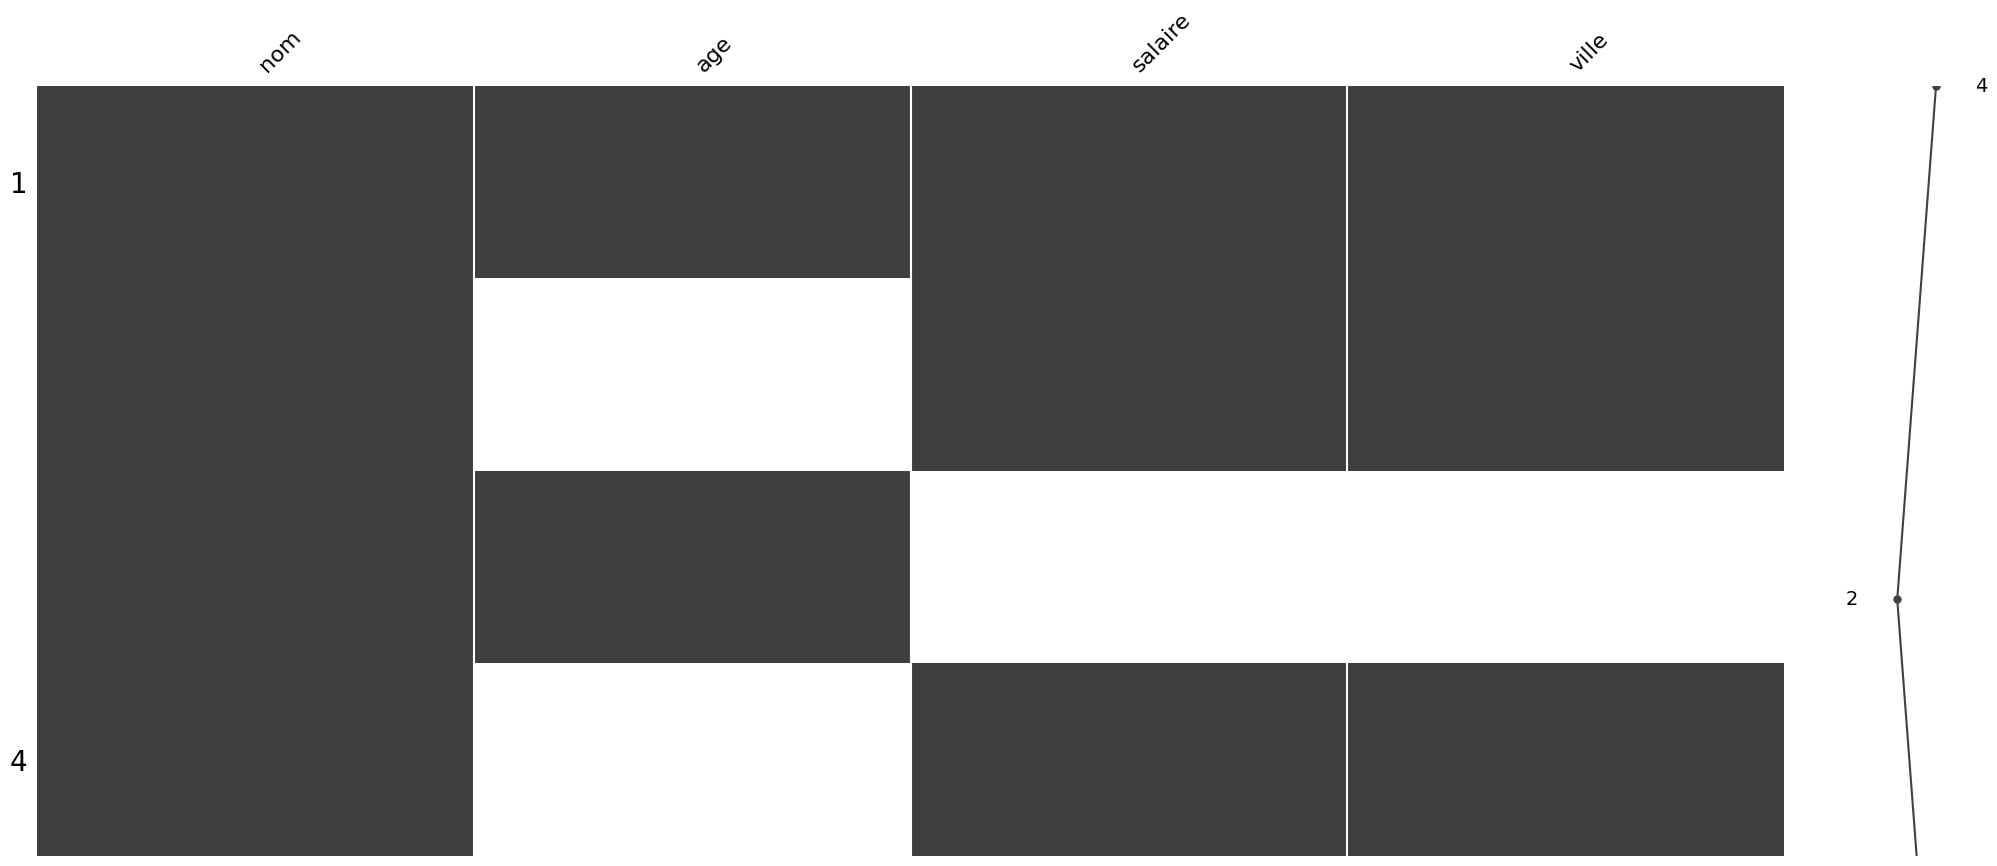

In [ ]:
# Installation de missingno (à faire une seule fois)
!pip install missingno

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Données d'exemple
data = {
    'nom': ['Ali', 'Sara', 'Omar', 'Imane'],
    'age': [25, np.nan, 30, np.nan],
    'salaire': [3000, 3200, np.nan, 4000],
    'ville': ['Rabat', 'Casablanca', None, 'Fès']
}

df = pd.DataFrame(data)

# 1) Détection des valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

# 2) Pourcentage de valeurs manquantes
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'colonne': missing_percent.index,
    'pourcentage_manquant': missing_percent.values
}).sort_values('pourcentage_manquant', ascending=False)

print("\nPourcentage de valeurs manquantes :")
print(missing_df)

# 3) Visualisations
msno.matrix(df)
plt.show()




In [ ]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Jeu de données concret
df = pd.DataFrame({
    "age": [20, 40, 60],
    "salaire": [2000, 4000, 6000]
})

print("Données originales :\n", df)

# 1) Instanciation de la classe MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# 2) Fit + transform : calcul des min/max et normalisation
scaled_values = scaler.fit_transform(df[["age", "salaire"]])

# 3) Reconstruction du DataFrame
df_scaled = pd.DataFrame(
    scaled_values,
    columns=["age_scaled", "salaire_scaled"]
)

print("\nDonnées normalisées :\n", df_scaled)



Données originales :
    age  salaire
0   20     2000
1   40     4000
2   60     6000

Données normalisées :
    age_scaled  salaire_scaled
0         0.0             0.0
1         0.5             0.5
2         1.0             1.0
